# Economic value of electricity-demand forecasts

### Procurement and imbalance-cost backtest

This notebook translates forecast errors into economic outcomes for a
hypothetical electricity retailer.

The weekly baseline, ML model and official REE D+1 forecast are evaluated
under the same simplified procurement and imbalance-settlement framework
over the January 2025–August 2026 out-of-sample period.

Results are reported both for the complete test sample and under normal
operating conditions, excluding the April 2025 blackout.

In [58]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from energy_forecasting.esios import (
    download_price,
)

from energy_forecasting.procurement import (
    compute_procurement_cost,
)

## 1. Forecast sample

The aligned forecast dataset produced in the previous notebook defines
the backtest universe. Market-price data are subsequently aligned to
these exact timestamps.

In [41]:
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

processed_dir = (
    project_root
    / "data"
    / "processed"
)

demand = pd.read_csv(
    processed_dir / "all_demands.csv",
    index_col="datetime_utc",
    parse_dates=["datetime_utc"],
)

demand.index = pd.to_datetime(
    demand.index,
    utc=True,
)

demand["datetime_local"] = pd.to_datetime(
    demand["datetime_local"],
    utc=True,
).dt.tz_convert("Europe/Madrid")

In [42]:
assert demand.index.is_unique
assert demand.index.is_monotonic_increasing
assert demand.isna().sum().sum() == 0
assert demand["is_blackout"].sum() == 19

print("Rows:", len(demand))
print("UTC start:", demand.index.min())
print("UTC end:", demand.index.max())
print(
    "Local start:",
    demand["datetime_local"].min(),
)
print(
    "Local end:",
    demand["datetime_local"].max(),
)

Rows: 14591
UTC start: 2024-12-31 23:00:00+00:00
UTC end: 2026-08-31 21:00:00+00:00
Local start: 2025-01-01 00:00:00+01:00
Local end: 2026-08-31 23:00:00+02:00


## 2. Market price data

Day-ahead and imbalance prices are obtained from ESIOS at their native
15-minute resolution and averaged to hourly frequency to match the
demand forecasts.

Because demand is represented as hourly average MW, the corresponding
one-hour energy quantity is numerically equal in MWh.

The download interval is derived directly from the forecast sample to
avoid silently dropping boundary observations.

In [43]:
cache_dir = (
    project_root
    / "data"
    / "raw"
    / "esios_prices"
)

start = demand.index.min()
end = (
    demand.index.max()
    + pd.Timedelta(hours=1)
)

day_ahead_price = download_price(
    indicator_id=600,
    geo_id=3,
    start=start,
    end=end,
    name="day_ahead_price",
    cache_dir=cache_dir,
)

imbalance_price_up = download_price(
    indicator_id=763,
    geo_id=8741,
    start=start,
    end=end,
    name="imbalance_price_up",
    cache_dir=cache_dir,
)

imbalance_price_down = download_price(
    indicator_id=764,
    geo_id=8741,
    start=start,
    end=end,
    name="imbalance_price_down",
    cache_dir=cache_dir,
)

In [44]:
price_series = [
    day_ahead_price,
    imbalance_price_up,
    imbalance_price_down,
]

for series in price_series:
    observations_per_hour = (
        series
        .resample("1h")
        .count()
        .reindex(demand.index)
    )

    assert (
        observations_per_hour == 4
    ).all()

In [45]:
prices_hourly = pd.concat(
    [
        day_ahead_price
        .resample("1h")
        .mean(),

        imbalance_price_up
        .resample("1h")
        .mean(),

        imbalance_price_down
        .resample("1h")
        .mean(),
    ],
    axis=1,
)

## 3. Forecast-price alignment

The forecast sample is preserved exactly. Missing market prices therefore
raise an explicit validation error rather than silently removing hours
from the backtest.

In [46]:
backtest = demand.join(
    prices_hourly,
    how="left",
)

price_columns = [
    "day_ahead_price",
    "imbalance_price_up",
    "imbalance_price_down",
]

assert len(backtest) == len(demand)
assert backtest.index.is_unique
assert backtest.index.is_monotonic_increasing

assert (
    backtest[price_columns]
    .notna()
    .all()
    .all()
)

print("Rows:", len(backtest))
print("Start:", backtest.index.min())
print("End:", backtest.index.max())

backtest.head()

Rows: 14591
Start: 2024-12-31 23:00:00+00:00
End: 2026-08-31 21:00:00+00:00


,datetime_local,demand_MW,forecast_ml,is_blackout,forecast_ree,forecast_lag168,day_ahead_price,imbalance_price_up,imbalance_price_down
datetime_utc,,,,,,,,,
2024-12-31 23:00:00+00:00,2025-01-01 00:00:00+01:00,22924.000000,20971.785247,False,23530.8,21646.500000,134.49,112.2525,133.3750
2025-01-01 00:00:00+00:00,2025-01-01 01:00:00+01:00,22185.916667,21096.561097,False,22670.3,20737.250000,131.59,114.5025,114.5025
2025-01-01 01:00:00+00:00,2025-01-01 02:00:00+01:00,20952.833333,19989.772718,False,21420.5,19471.416667,131.49,93.8950,140.2250
2025-01-01 02:00:00+00:00,2025-01-01 03:00:00+01:00,19774.750000,19386.697825,False,20285.0,18462.083333,131.42,118.2625,118.2350
2025-01-01 03:00:00+00:00,2025-01-01 04:00:00+01:00,18973.583333,19084.245030,False,19470.5,17824.333333,120.49,86.7200,118.6775


## 4. Procurement-cost comparison

Each forecast is interpreted as the quantity procured in the day-ahead
market. Any difference between forecast and realized demand is settled
at the corresponding imbalance price.

Perfect forecasting provides the economic reference: realized demand
would be purchased entirely at the day-ahead price.

The resulting incremental cost therefore measures the economic penalty
or benefit generated by forecast errors under the historical price
environment.

In [47]:
strategies = {
    "Weekly baseline":
        "forecast_lag168",

    "ML forecast":
        "forecast_ml",

    "REE D+1 forecast":
        "forecast_ree",
}

In [48]:
results_all = pd.DataFrame({
    name: compute_procurement_cost(
        backtest,
        forecast_col,
    )
    for name, forecast_col
    in strategies.items()
}).T

results_all.round(3)

,total_cost,shortfall_cost,surplus_cost,incremental_cost,incremental_cost_per_MWh
Weekly baseline,2.807589e+10,1.486559e+08,2.119636e+08,3.606194e+08,0.875
ML forecast,2.793836e+10,1.086208e+08,1.144643e+08,2.230851e+08,0.541
REE D+1 forecast,2.787726e+10,6.998427e+07,9.200781e+07,1.619921e+08,0.393


In [49]:
normal_operation = backtest.loc[
    ~backtest["is_blackout"]
].copy()

assert (
    len(backtest)
    - len(normal_operation)
    == 19
)

results_normal = pd.DataFrame({
    name: compute_procurement_cost(
        normal_operation,
        forecast_col,
    )
    for name, forecast_col
    in strategies.items()
}).T

results_normal.round(3)

,total_cost,shortfall_cost,surplus_cost,incremental_cost,incremental_cost_per_MWh
Weekly baseline,2.807429e+10,1.486559e+08,2.137820e+08,3.624379e+08,0.880
ML forecast,2.793681e+10,1.086208e+08,1.163377e+08,2.249585e+08,0.546
REE D+1 forecast,2.787586e+10,6.998427e+07,9.402861e+07,1.640129e+08,0.398


In [50]:
cost_summary = pd.DataFrame({
    "All-events cost (EUR/MWh)":
        results_all[
            "incremental_cost_per_MWh"
        ],

    "Normal-operation cost (EUR/MWh)":
        results_normal[
            "incremental_cost_per_MWh"
        ],
})

cost_summary.round(3)

,All-events cost (EUR/MWh),Normal-operation cost (EUR/MWh)
Weekly baseline,0.875,0.880
ML forecast,0.541,0.546
REE D+1 forecast,0.393,0.398


### Economic comparison

Forecast accuracy has direct economic consequences, but forecast error
alone does not determine procurement cost: the sign of the error and
the contemporaneous imbalance-price spread also matter.

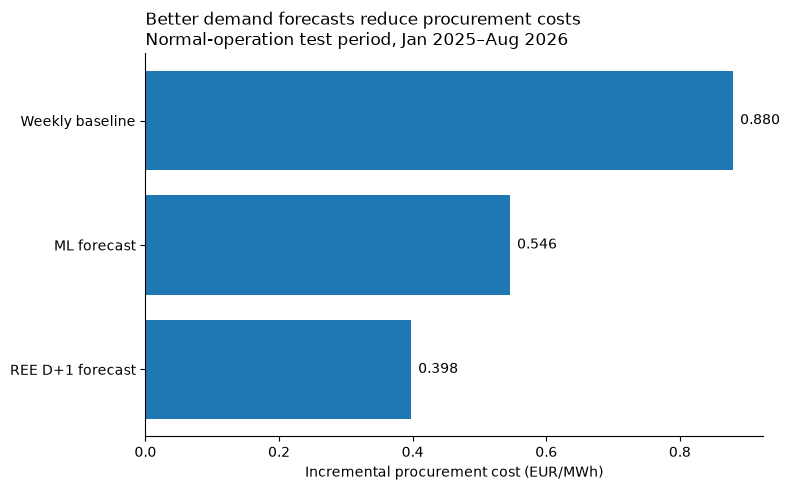

In [51]:
normal_cost = (
    results_normal[
        "incremental_cost_per_MWh"
    ]
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(
    figsize=(8, 5)
)

bars = ax.barh(
    normal_cost.index,
    normal_cost.values,
)

for bar, value in zip(
    bars,
    normal_cost.values,
):
    ax.text(
        value + 0.01,
        (
            bar.get_y()
            + bar.get_height() / 2
        ),
        f"{value:.3f}",
        va="center",
    )

ax.invert_yaxis()

ax.set_xlabel(
    "Incremental procurement cost (EUR/MWh)"
)

ax.set_title(
    "Better demand forecasts reduce procurement costs\n"
    "Normal-operation test period, Jan 2025–Aug 2026",
    loc="left",
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

## 5. Cost decomposition

Incremental forecast cost is decomposed into shortfall and surplus
components.

A shortfall occurs when realized demand exceeds day-ahead procurement.
A surplus occurs when the forecast exceeds realized demand.

The decomposition highlights that equally sized forecast errors need not
have equal economic consequences.

In [52]:
cost_decomposition = (
    results_normal[
        [
            "shortfall_cost",
            "surplus_cost",
        ]
    ]
    / normal_operation[
        "demand_MW"
    ].sum()
)

cost_decomposition.columns = [
    "Shortfall",
    "Surplus",
]

cost_decomposition.round(3)

,Shortfall,Surplus
Weekly baseline,0.361,0.519
ML forecast,0.264,0.283
REE D+1 forecast,0.170,0.228


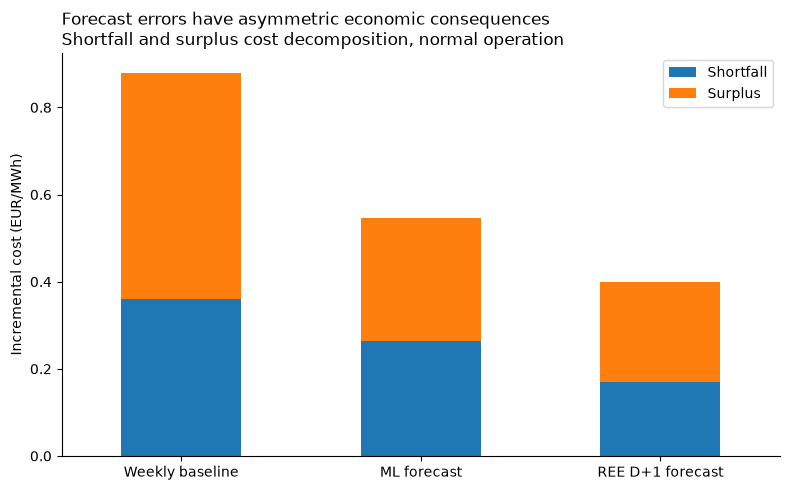

In [53]:
fig, ax = plt.subplots(
    figsize=(8, 5)
)

cost_decomposition.plot(
    kind="bar",
    stacked=True,
    ax=ax,
)

ax.set_ylabel(
    "Incremental cost (EUR/MWh)"
)

ax.set_xlabel("")

ax.set_title(
    "Forecast errors have asymmetric economic consequences\n"
    "Shortfall and surplus cost decomposition, normal operation",
    loc="left",
)

ax.legend(
    title=None,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 6. Business scaling

To translate the backtest into an interpretable business quantity,
incremental cost per MWh is scaled to hypothetical annual retail
portfolios.

The calculation assumes that the historical cost per MWh estimated
during normal operation is representative at each portfolio size.
This is a linear scaling exercise, not a claim that market impact or
portfolio composition would remain unchanged at arbitrary scale.

In [54]:
portfolio_sizes_TWh = [
    0.1,
    0.5,
    1.0,
    5.0,
    10.0,
]

portfolio_results = pd.DataFrame({
    "portfolio_TWh":
        portfolio_sizes_TWh
})

portfolio_MWh = (
    portfolio_results["portfolio_TWh"]
    * 1_000_000
)

normal_cost_per_MWh = {
    "lag168":
        results_normal.loc[
            "Weekly baseline",
            "incremental_cost_per_MWh",
        ],

    "ml":
        results_normal.loc[
            "ML forecast",
            "incremental_cost_per_MWh",
        ],

    "ree":
        results_normal.loc[
            "REE D+1 forecast",
            "incremental_cost_per_MWh",
        ],
}

for (
    name,
    cost_per_MWh,
) in normal_cost_per_MWh.items():

    portfolio_results[
        f"{name}_cost_EUR"
    ] = (
        portfolio_MWh
        * cost_per_MWh
    )

portfolio_results[
    "ml_savings_vs_lag168_EUR"
] = (
    portfolio_results[
        "lag168_cost_EUR"
    ]
    - portfolio_results[
        "ml_cost_EUR"
    ]
)

portfolio_results[
    "ree_savings_vs_ml_EUR"
] = (
    portfolio_results[
        "ml_cost_EUR"
    ]
    - portfolio_results[
        "ree_cost_EUR"
    ]
)

portfolio_results.round(2)

,portfolio_TWh,lag168_cost_EUR,ml_cost_EUR,ree_cost_EUR,ml_savings_vs_lag168_EUR,ree_savings_vs_ml_EUR
0,0.1,88012.66,54627.82,39828.09,33384.83,14799.73
1,0.5,440063.28,273139.12,199140.45,166924.16,73998.67
2,1.0,880126.55,546278.24,398280.91,333848.31,147997.33
3,5.0,4400632.75,2731391.20,1991404.53,1669241.56,739986.67
4,10.0,8801265.50,5462782.39,3982809.06,3338483.11,1479973.33


In [55]:
one_TWh = (
    portfolio_results
    .loc[
        portfolio_results[
            "portfolio_TWh"
        ].eq(1.0)
    ]
    .iloc[0]
)

print(
    "ML savings vs weekly baseline "
    "for a 1 TWh portfolio: "
    f"€{one_TWh['ml_savings_vs_lag168_EUR']:,.0f}"
)

print(
    "Additional savings from REE vs ML "
    "for a 1 TWh portfolio: "
    f"€{one_TWh['ree_savings_vs_ml_EUR']:,.0f}"
)

ML savings vs weekly baseline for a 1 TWh portfolio: €333,848
Additional savings from REE vs ML for a 1 TWh portfolio: €147,997


## 7. Backtest artifacts

The aligned hourly backtest and aggregated business-scaling results are
saved for downstream SQL and reporting analysis.

In [56]:
backtest.to_csv(
    processed_dir / "costs.csv",
    index=True,
)

portfolio_results.to_csv(
    processed_dir
    / "portfolio_results.csv",
    index=False,
)

cost_summary.to_csv(
    processed_dir
    / "procurement_summary.csv",
    index=True,
)

## Conclusions

The economic backtest converts forecasting performance into a directly
interpretable procurement objective.

The ML forecast substantially improves on the weekly baseline, showing
that the additional modeling and feature-engineering effort has tangible
economic value. The official REE D+1 forecast remains the strongest
benchmark.

The comparison also illustrates that statistical accuracy and economic
value are not identical objectives: procurement cost depends not only on
forecast-error magnitude, but also on its direction and on the prevailing
day-ahead and imbalance prices.